# 3.1 Logistic regression

Log-odds, the sigmoid, maximum-likelihood estimation, and reading a fitted
model's coefficients -- on the churn target used by every classification
notebook in this folder.

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

Every classification notebook predicts the **same target, from the same
features, on the same train/test split** -- so the confusion matrix/ROC/AUC
numbers below are directly comparable to the other technique notebooks in
this folder.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.model_selection import train_test_split
from plotting import plot_confusion, plot_roc, plot_lift

features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
X = df[features]
y = df["churned"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("train:", Xtr.shape, " test:", Xte.shape, " churn rate (train/test):", round(ytr.mean(),3), round(yte.mean(),3))

train: (210, 7)  test: (90, 7)  churn rate (train/test): 0.338 0.344


## The sigmoid function

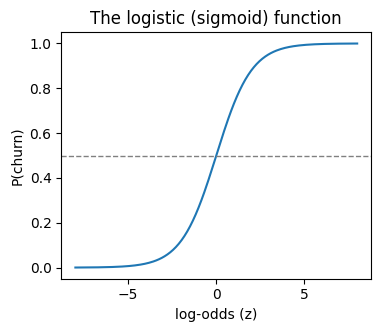

In [3]:
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))
fig, ax = plt.subplots(figsize=(4, 3.2))
ax.plot(z, sigmoid)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("log-odds (z)"); ax.set_ylabel("P(churn)"); ax.set_title("The logistic (sigmoid) function")
plt.show()

## Estimation via maximum likelihood

In [4]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
coefs = pd.Series(clf.coef_[0], index=features).sort_values()
coefs

satisfaction    -0.442218
tenure_months   -0.033695
monthly_usage   -0.000109
age              0.005944
income_k         0.011412
discount_pct     0.034628
support_calls    0.169552
dtype: float64

Reading a coefficient: holding the other features fixed, one extra unit of
a feature multiplies the **odds** of churn by `exp(coefficient)` -- e.g. a
positive `support_calls` coefficient means more support calls are
associated with higher churn odds, matching the "reading a fitted model"
slide.

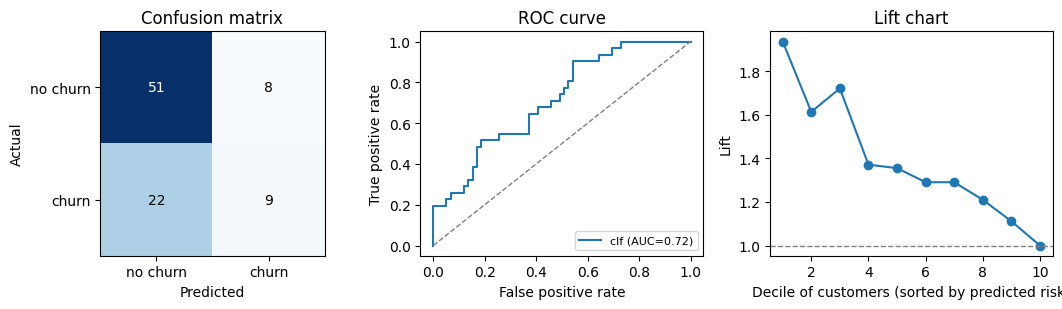

AUC: 0.715


In [5]:
y_pred = clf.predict(Xte)
y_score = clf.predict_proba(Xte)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
plot_confusion(yte, y_pred, ax=axes[0])
auc_val = plot_roc(yte, y_score, ax=axes[1], label="clf")
plot_lift(yte, y_score, ax=axes[2])
plt.tight_layout(); plt.show()
print("AUC:", round(auc_val, 3))

**Wrap-up**: logistic regression gives an interpretable, probabilistic
baseline -- the AUC/lift above is the number to beat as we try k-NN, SVM,
trees, ensembles and a small neural net on the exact same split.